# Clothes segmentation: Colab training runner (Part 2)

This notebook only orchestrates. All logic lives in the `.py` files of the project.

**Before running**
1. `Runtime > Change runtime type`: choose **L4 GPU**.
2. Run the cells from top to bottom. Cell 3 asks you to upload the new `clothseg_code.zip` (from the project folder on your computer) once.
3. Every cell is safe to rerun. If the session dies, open the notebook again and run everything from the top: finished work is skipped and training continues from the last checkpoint.

**What it does:** prepares the data, proves that resume works, then runs bake-off round 1 (4 models, 5 epochs each, about 3.5 hours on an L4).

## 1. Settings

In [1]:
REPO_URL = ""  # e.g. "https://github.com/<your-user>/clothes-segmentation.git"; leave empty to use the uploaded zip

DRIVE_ROOT = "/content/drive/MyDrive/clothseg"   # everything persistent lives here
CODE_DIR = "/content/clothes-segmentation"       # local copy of the code
CODE_VERSION = "2"                                # version of clothseg_code.zip this notebook needs
HEIGHT, WIDTH = 576, 384                          # training resolution (H, W)
SESSION_BUDGET_MIN = 600                          # training stops cleanly and saves this many minutes after cell 2 ran

MODELS = ["segformer_b2", "segformer_b3", "segformer_b4", "upernet_convnext_tiny"]
SCHEDULE_EPOCHS = 12                              # length of the learning-rate schedule (same for every model)
ROUND1_EPOCHS = 5                                 # round 1 stops here

## 2. Mount Drive and show the environment

In [2]:
import os, platform, shutil, time
from google.colab import drive

drive.mount("/content/drive")
os.makedirs(DRIVE_ROOT, exist_ok=True)
SESSION_START = time.time()

def minutes_left():
    """Minutes of the session budget that remain; passed to every training command."""
    return max(1, SESSION_BUDGET_MIN - (time.time() - SESSION_START) / 60)

import torch, transformers
print("python      ", platform.python_version(), "| torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU         ", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE: change the runtime type to a GPU")
if torch.cuda.is_available():
    print("GPU memory  ", f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
print("CPU cores   ", os.cpu_count())
print("local disk  ", f"{shutil.disk_usage('/content').free / 1024**3:.0f} GB free")
print("Drive       ", f"{shutil.disk_usage(DRIVE_ROOT).free / 1024**3:.0f} GB free")
assert torch.cuda.is_available(), "No GPU. Choose Runtime > Change runtime type > L4 GPU, then run again."

Mounted at /content/drive
python       3.13.15 | torch 2.11.0+cu130 | transformers 5.18.0
GPU          NVIDIA L4
GPU memory   22.0 GB
CPU cores    12
local disk   193 GB free
Drive        184 GB free


## 3. Get the code

In [5]:
import subprocess, zipfile

def code_version(folder):
    path = os.path.join(folder, "VERSION")
    return open(path).read().strip() if os.path.exists(path) else "1"

os.chdir("/content")
if REPO_URL:
    if os.path.isdir(f"{CODE_DIR}/.git"):
        print(subprocess.run(["git", "-C", CODE_DIR, "pull"], capture_output=True, text=True).stdout)
    else:
        r = subprocess.run(["git", "clone", REPO_URL, CODE_DIR], capture_output=True, text=True)
        assert r.returncode == 0, f"git clone failed. Is the URL correct and the repository public?\n{r.stderr}"
elif os.path.isdir(f"{DRIVE_ROOT}/code") and code_version(f"{DRIVE_ROOT}/code") == CODE_VERSION:
    shutil.rmtree(CODE_DIR, ignore_errors=True)
    shutil.copytree(f"{DRIVE_ROOT}/code", CODE_DIR)
    print(f"code version {CODE_VERSION} copied from Drive")
else:
    from google.colab import files
    if os.path.exists("clothseg_code.zip"):
        os.remove("clothseg_code.zip")   # otherwise Colab renames the new upload
    print(f"Drive has code version {code_version(f'{DRIVE_ROOT}/code')}, this notebook needs version {CODE_VERSION}.")
    print("Choose the NEW clothseg_code.zip from the project folder on your computer.")
    uploaded = files.upload()
    assert "clothseg_code.zip" in uploaded, f"Expected a file named clothseg_code.zip, got {list(uploaded)}."
    for folder in (CODE_DIR, f"{DRIVE_ROOT}/code"):   # the Drive copy is used by later sessions
        shutil.rmtree(folder, ignore_errors=True)
        with zipfile.ZipFile("clothseg_code.zip") as z:
            z.extractall(folder)
    print("code uploaded and saved to Drive")

assert code_version(CODE_DIR) == CODE_VERSION, (
    f"The code is version {code_version(CODE_DIR)} but this notebook needs version {CODE_VERSION}. "
    "You uploaded an old clothseg_code.zip. Run this cell again and choose the new one.")
for needed in ("scripts/train.py", "scripts/resume_test.py", "src/clothseg/engine.py", "requirements.txt"):
    assert os.path.exists(f"{CODE_DIR}/{needed}"), f"{needed} is missing from {CODE_DIR}. Check the upload or the repository."
os.chdir(CODE_DIR)
print("code ready in", os.getcwd(), "| version", code_version(CODE_DIR))

code version 2 copied from Drive
code ready in /content/clothes-segmentation | version 2


## 4. Install requirements

In [6]:
!pip install -q -r requirements.txt
import segmentation_models_pytorch, timm, cv2
print("segmentation_models_pytorch", segmentation_models_pytorch.__version__, "| timm", timm.__version__, "| opencv", cv2.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 14.2 MB/s eta 0:00:00
segmentation_models_pytorch 0.5.0 | timm 1.0.30 | opencv 4.14.0


## 5. Prepare the dataset

Copies the archive from Drive and extracts it (about a minute). It then moves near-duplicate photos that sit in more than one split into train, so validation and test contain no copy of a training image.

In [7]:
!python scripts/prepare_data.py --drive-root "{DRIVE_ROOT}" --height {HEIGHT} --width {WIDTH}

[prepare] cache name: atr_576x384 | local: /content/data/atr_576x384 | Drive archive: /content/drive/MyDrive/clothseg/data/cache/atr_576x384.tar
[prepare] free local disk: 193.3 GB
[prepare] found archive on Drive (1.6 GB). Copying and extracting...
[storage] copied atr_576x384.tar (1.6 GB) -> /content/data in 22s
[storage] extracted atr_576x384.tar -> /content/data in 13s
[prepare] done in 37s
[splits] moved 56 val/test near-duplicates of training images into train. New sizes: train=16038, val=690, test=960


## 6. Resume test (about 5 minutes)

Trains a tiny experiment twice, once without interruption and once killed and resumed twice, then compares them step by step. It must end with **RESUME TEST PASSED** before the long runs start.

In [ ]:
!python scripts/resume_test.py --drive-root "{DRIVE_ROOT}" --height {HEIGHT} --width {WIDTH} 2>&1 | tee /content/resume_test.log
assert "RESUME TEST PASSED" in open("/content/resume_test.log").read(), "The resume test did not pass. Do not start the long runs; send me the output above."


===== _resume_test_A  =====
Loading weights: 100%|██████████| 364/364 [00:00<00:00, 19667.47it/s]
[model] segformer_b2: 27.4 M parameters (encoder 24.2 M, head 3.2 M) | 15 classes | encoder: ImageNet-pretrained weights loaded, head: new
[train] FRESH START in /content/drive/MyDrive/clothseg/runs/_resume_test_A
[train] segformer_b2 | 15 classes | 576x384 | batch 16 | fp16 True | NVIDIA L4 | 8 workers
[train] data: train 192, val 32 images (fingerprint 8b4d7a60ccb0) | 12 steps/epoch
[train] schedule: 2 epochs = 24 steps; this command runs until the end of epoch 2; time budget 280 min; checkpoint every 10 min
/content/clothes-segmentation/src/clothseg/engine.py:240: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  if not math.isfinite(float(loss)):
[train] epoch 1/2 step 1/12 | loss 1.9399 (ce 2.9477

## 7. Bake-off round 1

Trains each model for 5 epochs of a 12-epoch schedule, one after another. Expect roughly 40 to 65 minutes per model.

If the session dies, run the notebook again from the top: finished models are skipped and the interrupted one continues from its last checkpoint.

In [ ]:
for m in MODELS:
    print("\n" + "=" * 100 + f"\n{m}\n" + "=" * 100)
    budget = int(minutes_left())
    !python scripts/train.py --drive-root "{DRIVE_ROOT}" --run-name r1_{m} --model {m} --height {HEIGHT} --width {WIDTH} --epochs {SCHEDULE_EPOCHS} --stop-after-epoch {ROUND1_EPOCHS} --time-budget-min {budget}


segformer_b2
Loading weights: 100% 364/364 [00:00<00:00, 16335.27it/s]
[model] segformer_b2: 27.4 M parameters (encoder 24.2 M, head 3.2 M) | 15 classes | encoder: ImageNet-pretrained weights loaded, head: new
[train] FRESH START in /content/drive/MyDrive/clothseg/runs/r1_segformer_b2
[train] segformer_b2 | 15 classes | 576x384 | batch 16 | fp16 True | NVIDIA L4 | 8 workers
[train] data: train 16038, val 690 images (fingerprint 8b4d7a60ccb0) | 1002 steps/epoch
[train] schedule: 12 epochs = 12024 steps; this command runs until the end of epoch 5; time budget 595 min; checkpoint every 10 min
/content/clothes-segmentation/src/clothseg/engine.py:240: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  if not math.isfinite(float(loss)):
[train] epoch 1/12 step 50/1002 | loss 1.8358 (ce 2.7462, lovasz 0.92

## 8. Compare the models

Comparing 4 runs at epoch 2 (validation set)

rank run                          garment mIoU    mIoU cloth IoU upper-clo     pants     skirt     dress last gain min/epoch  img/s
-----------------------------------------------------------------------------------------------------------------------------------
1    r1_segformer_b3                    0.6555  0.7186    0.9077    0.7983    0.7909    0.6658    0.6472   +0.0527      11.7   22.9
2    r1_upernet_convnext_tiny           0.6543  0.7204    0.9112    0.7956    0.7970    0.6372    0.5870   +0.0372       8.4   32.2
3    r1_segformer_b4                    0.6536  0.7168    0.9078    0.7949    0.7834    0.6507    0.6437   +0.0413      13.8   19.3
4    r1_segformer_b2                    0.6225  0.6935    0.9029    0.7730    0.7688    0.6305    0.6242   +0.0437       9.9   27.0

columns: 'cloth IoU' = any garment vs everything else; 'last gain' = garment mIoU change over the last epoch (a large value means the model is still improving fa

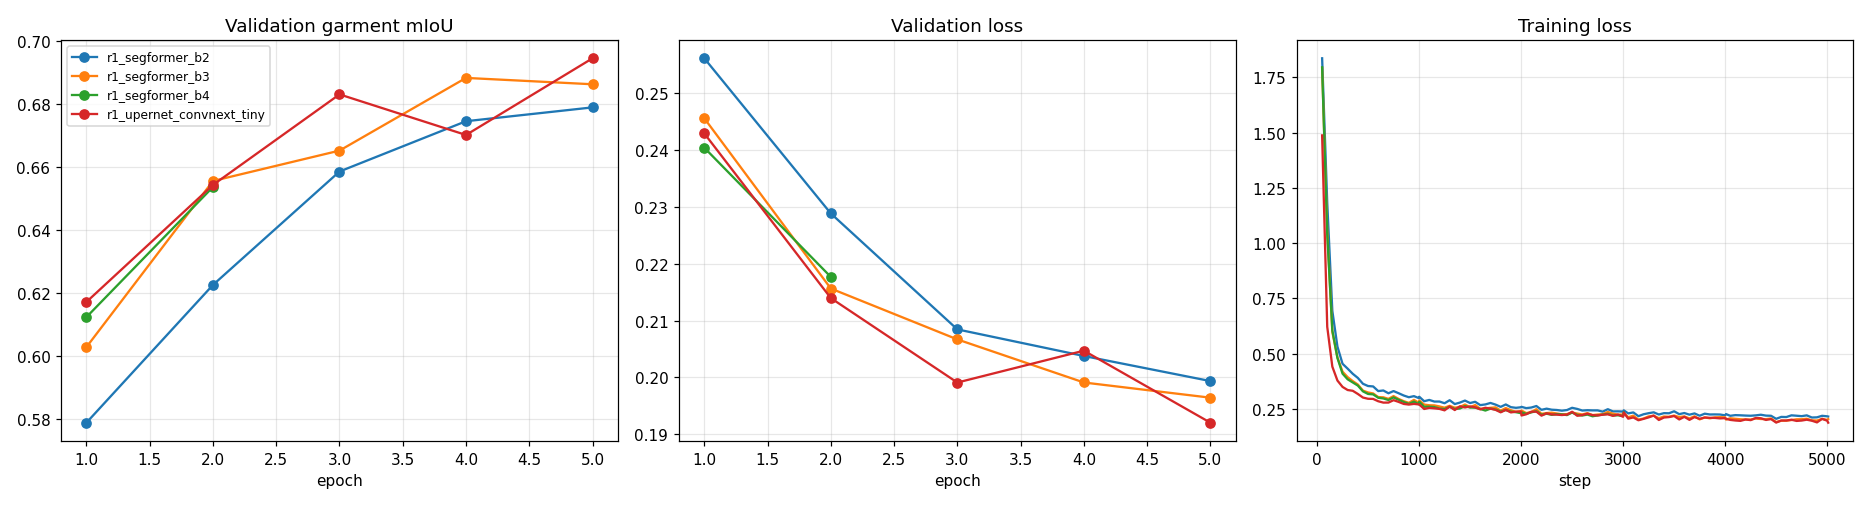

In [ ]:
!python scripts/compare_runs.py --drive-root "{DRIVE_ROOT}" --prefix r1_

from IPython.display import Image, display
display(Image(f"{DRIVE_ROOT}/reports/compare_r1.png"))

[checkpoint] loaded step_00002735.pt
[model] segformer_b4: 64.0 M parameters (encoder 60.8 M, head 3.2 M) | 15 classes | weights not initialised from ImageNet
[train] RESUMED from epoch 3, batch 731/1002 (global step 2735/12024); best mIoU so far 0.7168; 38 min trained in earlier sessions; model weights restored from the checkpoint
[train] segformer_b4 | 15 classes | 576x384 | batch 16 | fp16 True | NVIDIA L4 | 8 workers
[train] data: train 16038, val 690 images (fingerprint 8b4d7a60ccb0) | 1002 steps/epoch
[train] schedule: 12 epochs = 12024 steps; this command runs until the end of epoch 5; time budget 332 min; checkpoint every 10 min
/content/clothes-segmentation/src/clothseg/engine.py:240: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  if not math.isfinite(float(loss)):
[train] epoch 3/12 ste

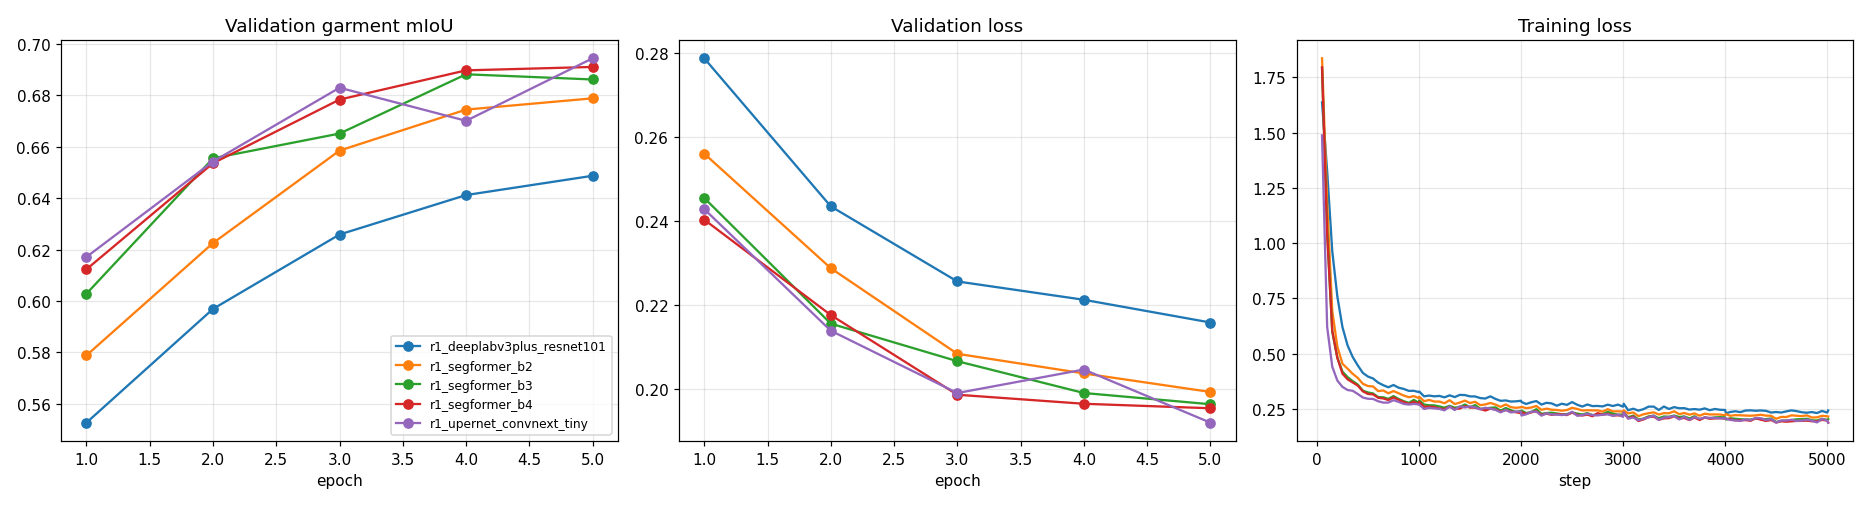

In [ ]:
import os
from IPython.display import Image, display

os.chdir(CODE_DIR)
m = "segformer_b4"
budget = int(minutes_left())
!python scripts/train.py --drive-root "{DRIVE_ROOT}" --run-name r1_{m} --model {m} --height {HEIGHT} --width {WIDTH} --epochs {SCHEDULE_EPOCHS} --stop-after-epoch {ROUND1_EPOCHS} --time-budget-min {budget}

!python scripts/compare_runs.py --drive-root "{DRIVE_ROOT}" --prefix r1_ --at-epoch {ROUND1_EPOCHS} --out "{DRIVE_ROOT}/reports/compare_r1_with_extra.png"
display(Image(f"{DRIVE_ROOT}/reports/compare_r1_with_extra.png"))

In [ ]:
import glob, os, pandas as pd

for d in sorted(glob.glob(f"{DRIVE_ROOT}/runs/r1_*")):
    path = f"{d}/val_log.csv"
    if not os.path.exists(path):
        print(os.path.basename(d), "| no validated epoch yet\n")
        continue
    v = pd.read_csv(path)
    print(os.path.basename(d), "| epochs done:", len(v))
    print(v[["epoch", "miou", "garment_miou", "iou_upper-clothes", "iou_pants", "iou_skirt", "iou_dress", "train_min"]].to_string(index=False), "\n")


r1_deeplabv3plus_resnet101 | epochs done: 5
 epoch    miou  garment_miou  iou_upper-clothes  iou_pants  iou_skirt  iou_dress  train_min
     1 0.63322       0.55259            0.72041    0.72352    0.55619    0.54786       8.16
     2 0.67319       0.59688            0.75649    0.76089    0.60405    0.58929      16.00
     3 0.69480       0.62586            0.77698    0.78314    0.64063    0.61643      23.84
     4 0.70739       0.64122            0.78758    0.78996    0.61028    0.60069      31.67
     5 0.71440       0.64873            0.78395    0.79720    0.63536    0.57434      39.51 

r1_segformer_b2 | epochs done: 5
 epoch    miou  garment_miou  iou_upper-clothes  iou_pants  iou_skirt  iou_dress  train_min
     1 0.65842       0.57879            0.74061    0.73204    0.54565    0.56954      10.05
     2 0.69351       0.62253            0.77297    0.76882    0.63053    0.62420      19.86
     3 0.72231       0.65853            0.79556    0.79909    0.66126    0.66150      29.66
 

DeepLabV3+ is already in /content/clothes-segmentation/src/clothseg/models.py
[checkpoint] loaded step_00005010.pt
[model] deeplabv3plus_resnet101: 45.7 M parameters (encoder 42.5 M, head 3.2 M) | 15 classes | weights not initialised from ImageNet
[train] RESUMED from epoch 6, batch 0/1002 (global step 5010/12024); best mIoU so far 0.7144; 40 min trained in earlier sessions; model weights restored from the checkpoint
[train] deeplabv3plus_resnet101 | 15 classes | 576x384 | batch 16 | fp16 True | NVIDIA L4 | 8 workers
[train] data: train 16038, val 690 images (fingerprint 8b4d7a60ccb0) | 1002 steps/epoch
[train] schedule: 12 epochs = 12024 steps; this command runs until the end of epoch 5; time budget 299 min; checkpoint every 10 min
[train] Nothing to do: epoch 5 is already complete for this run.
Comparing 5 runs at epoch 5 (validation set)

rank run                          garment mIoU    mIoU cloth IoU upper-clo     pants     skirt     dress last gain min/epoch  img/s
--------------

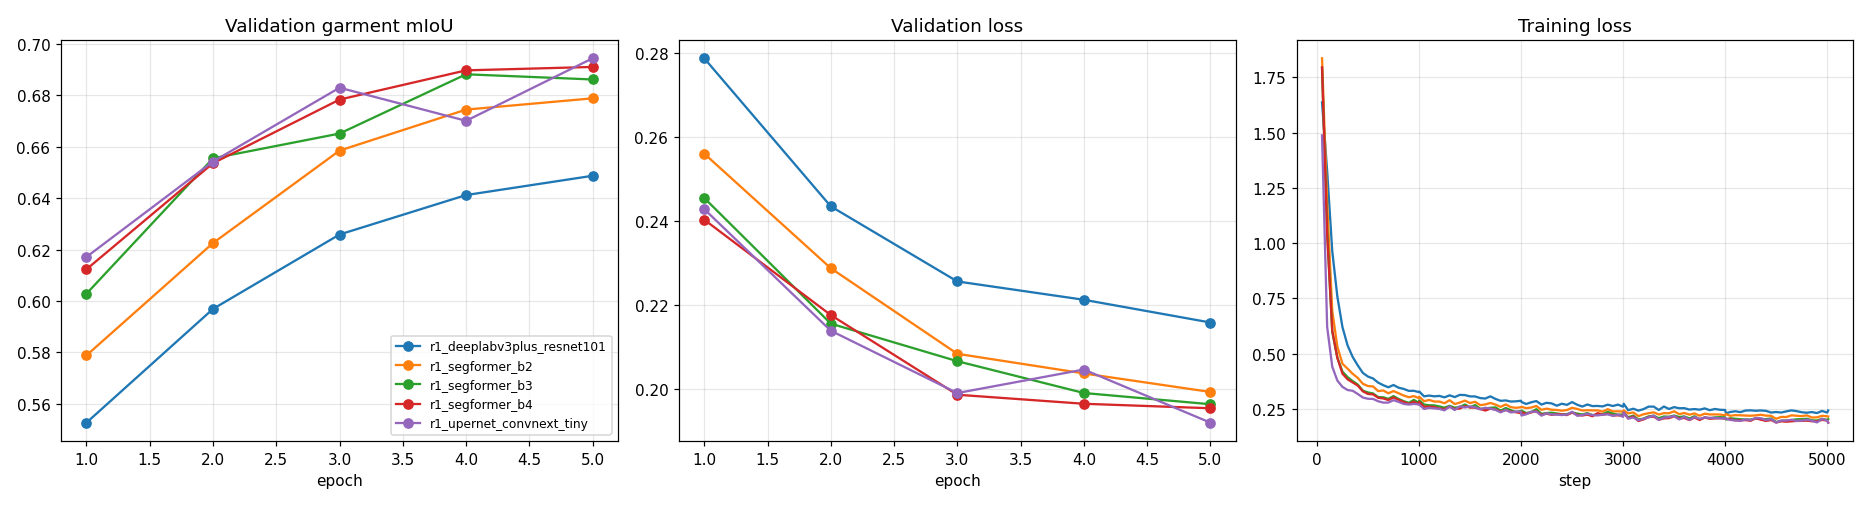

In [ ]:
# Paste this whole block into ONE new cell at the end of the notebook you are running,
# and run it after cell 8 (the comparison) has finished.
# It adds DeepLabV3+ to the code of this session, trains it with the same settings
# as the other models, and prints the comparison again with all five models.

import os

EXTRA_MODEL = "deeplabv3plus_resnet101"
models_py = f"{CODE_DIR}/src/clothseg/models.py"
src = open(models_py).read()

if EXTRA_MODEL not in src:
    old_names = '"upernet_convnext_tiny")'
    old_branch = "        encoder = net.encoder\n    else:"
    assert src.count(old_names) == 1 and src.count(old_branch) == 1, (
        "models.py is not the version this cell expects. Do not continue; send me this message.")
    src = src.replace(old_names, '"upernet_convnext_tiny", "deeplabv3plus_resnet101")')
    src = src.replace(old_branch, (
        "        encoder = net.encoder\n"
        '    elif name == "deeplabv3plus_resnet101":\n'
        "        import segmentation_models_pytorch as smp\n"
        "\n"
        "        # The classic human-parsing baseline: ResNet-101 encoder, atrous spatial pyramid pooling decoder.\n"
        '        net = smp.DeepLabV3Plus(encoder_name="resnet101", encoder_weights="imagenet" if pretrained else None, classes=num_classes)\n'
        "        encoder = net.encoder\n"
        "    else:"))
    open(models_py, "w").write(src)
    print("DeepLabV3+ added to", models_py)
else:
    print("DeepLabV3+ is already in", models_py)

os.chdir(CODE_DIR)
budget = int(minutes_left())
!python scripts/train.py --drive-root "{DRIVE_ROOT}" --run-name r1_{EXTRA_MODEL} --model {EXTRA_MODEL} --height {HEIGHT} --width {WIDTH} --epochs {SCHEDULE_EPOCHS} --stop-after-epoch {ROUND1_EPOCHS} --time-budget-min {budget}

!python scripts/compare_runs.py --drive-root "{DRIVE_ROOT}" --prefix r1_ --at-epoch {ROUND1_EPOCHS} --out "{DRIVE_ROOT}/reports/compare_r1_with_extra.png"
from IPython.display import Image, display
display(Image(f"{DRIVE_ROOT}/reports/compare_r1_with_extra.png"))


## What to send back

Copy the full text output of cells 6 and 8, and the `[val]` lines of cell 7. If a cell fails, copy the whole error message.

**Stop here.** Round 2 below is only run after we have picked the top two models together.

## 9. Bake-off round 2 (only after we choose the top two)

Put the two chosen model names in `TOP2`. The same runs continue from epoch 6 to epoch 12.

In [8]:
import os, pandas as pd

os.chdir(CODE_DIR)
TOP2 = ["upernet_convnext_tiny", "segformer_b3", "segformer_b4"]


for m in TOP2:
    print("\n" + "=" * 100 + f"\n{m}\n" + "=" * 100)
    budget = int(minutes_left())
    !python scripts/train.py --drive-root "{DRIVE_ROOT}" --run-name r1_{m} --model {m} --height {HEIGHT} --width {WIDTH} --epochs {SCHEDULE_EPOCHS} --time-budget-min {budget}

for m in TOP2:
    v = pd.read_csv(f"{DRIVE_ROOT}/runs/r1_{m}/val_log.csv")
    print(f"\n{m} | epochs done: {len(v)}")
    print(v[["epoch", "miou", "garment_miou", "iou_upper-clothes", "iou_pants", "iou_skirt", "iou_dress", "val_loss", "train_min"]].to_string(index=False))



upernet_convnext_tiny
[checkpoint] loaded step_00012024.pt
[model] upernet_convnext_tiny: 37.0 M parameters (encoder 27.8 M, head 9.2 M) | 15 classes | weights not initialised from ImageNet
[train] RESUMED from epoch 13, batch 0/1002 (global step 12024/12024); best mIoU so far 0.7698; 99 min trained in earlier sessions; model weights restored from the checkpoint
[train] upernet_convnext_tiny | 15 classes | 576x384 | batch 16 | fp16 True | NVIDIA L4 | 8 workers
[train] data: train 16038, val 690 images (fingerprint 8b4d7a60ccb0) | 1002 steps/epoch
[train] schedule: 12 epochs = 12024 steps; this command runs until the end of epoch 12; time budget 593 min; checkpoint every 10 min
[train] Nothing to do: epoch 12 is already complete for this run.

segformer_b3
[checkpoint] loaded step_00010020.pt
config.json: 100% 70.0k/70.0k [00:00<00:00, 36.4MB/s]
[model] segformer_b3: 47.2 M parameters (encoder 44.1 M, head 3.2 M) | 15 classes | weights not initialised from ImageNet
[train] RESUMED from

In [9]:
import pandas as pd

for m in ["upernet_convnext_tiny", "segformer_b3", "segformer_b4"]:
    v = pd.read_csv(f"{DRIVE_ROOT}/runs/r1_{m}/val_log.csv")
    print(f"\n{m} | epochs done: {len(v)}")
    print(v[["epoch", "miou", "garment_miou", "iou_upper-clothes", "iou_pants", "iou_skirt", "iou_dress", "val_loss", "train_min"]].to_string(index=False))



upernet_convnext_tiny | epochs done: 12
 epoch    miou  garment_miou  iou_upper-clothes  iou_pants  iou_skirt  iou_dress  val_loss  train_min
     1 0.68757       0.61712            0.75732    0.77447    0.61142    0.56338   0.24288       8.69
     2 0.72041       0.65427            0.79560    0.79697    0.63725    0.58704   0.21395      16.88
     3 0.74119       0.68302            0.80645    0.80604    0.69434    0.64914   0.19911      25.10
     4 0.73290       0.67013            0.80781    0.79290    0.62338    0.61482   0.20471      33.31
     5 0.75103       0.69448            0.82018    0.82073    0.68314    0.65377   0.19206      41.51
     6 0.75583       0.70129            0.82507    0.82462    0.70573    0.67648   0.18836      50.04
     7 0.75422       0.69910            0.82166    0.81827    0.68374    0.68468   0.18805      58.30
     8 0.75604       0.69987            0.82018    0.81565    0.68060    0.65215   0.19086      66.50
     9 0.76246       0.70833            0